# Cardiovascular Risk Analysis - 10 Regression Algorithms (Combined Notebook)

**Regression target:** `ap_hi` (systolic blood pressure, mmHg)
**Dataset:** `HeartFailureDataset.csv` (~70,000 patient records)

> `cardio` is a binary outcome, so it cannot be a regression target. As in both original regression notebooks, `ap_hi` is used. Please confirm this with your instructor.

This notebook combines two regression notebooks into one, using **one common preprocessing pipeline** (the same pipeline used in the combined classification notebook) for all models:

| Part | Algorithms |
|---|---|
| **Part A** (first notebook, kept first) | Linear Regression, Ridge, Lasso, ElasticNet, Polynomial Regression |
| **Part B** (second notebook) | Decision Tree, Random Forest, Gradient Boosting, Support Vector Regressor (SVR), K-Nearest Neighbors (KNN) |

**Pipeline:** load -> inspect -> missing values / duplicates -> outlier detection and treatment (IQR capping) -> encoding -> stratified train/test split -> scaling -> PCA -> hyper-parameter tuning and training of all 10 models -> evaluation (table, plots, cross-validation) -> inference.

> Place `HeartFailureDataset.csv` in the same folder as this notebook. Requires scikit-learn >= 1.2.

## 1. Load the dataset

In [1]:
import warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.decomposition import PCA

# Part A models (first notebook)
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet

# Part B models (second notebook)
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
TARGET = "ap_hi"

In [2]:
DATA_PATH = "HeartFailureDataset.csv"
df = pd.read_csv(DATA_PATH)
df.head()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62,110,80,1,1,0,0,1,0
1,1,20228,1,156,85,140,90,3,1,0,0,1,1
2,2,18857,1,165,64,130,70,3,1,0,0,0,1
3,3,17623,2,169,82,150,100,1,1,0,0,1,1
4,4,17474,1,156,56,100,60,1,1,0,0,0,0


## 2. Data inspection and cleaning

In [3]:
print("Shape:", df.shape)
print()
df.info()

Shape: (70000, 13)

<class 'pandas.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   id           70000 non-null  int64
 1   age          70000 non-null  int64
 2   gender       70000 non-null  int64
 3   height       70000 non-null  int64
 4   weight       70000 non-null  int64
 5   ap_hi        70000 non-null  int64
 6   ap_lo        70000 non-null  int64
 7   cholesterol  70000 non-null  int64
 8   gluc         70000 non-null  int64
 9   smoke        70000 non-null  int64
 10  alco         70000 non-null  int64
 11  active       70000 non-null  int64
 12  cardio       70000 non-null  int64
dtypes: int64(13)
memory usage: 6.9 MB


In [4]:
display(df.describe().T)
print("Duplicate rows :", df.duplicated().sum())
print()
print("Missing values per column:")
print(df.isnull().sum())

,count,mean,std,min,25%,50%,75%,max
id,70000.0,49972.419900,28851.302323,0.0,25006.75,50001.5,74889.25,99999.0
age,70000.0,19468.865814,2467.251667,10798.0,17664.00,19703.0,21327.00,23713.0
gender,70000.0,1.349571,0.476838,1.0,1.00,1.0,2.00,2.0
height,70000.0,164.359229,8.210126,55.0,159.00,165.0,170.00,250.0
weight,70000.0,74.205543,14.395829,10.0,65.00,72.0,82.00,200.0
ap_hi,70000.0,128.817714,154.011381,-150.0,120.00,120.0,140.00,16020.0
ap_lo,70000.0,96.630414,188.472530,-70.0,80.00,80.0,90.00,11000.0
cholesterol,70000.0,1.366871,0.680250,1.0,1.00,1.0,2.00,3.0
gluc,70000.0,1.226457,0.572270,1.0,1.00,1.0,1.00,3.0
smoke,70000.0,0.088129,0.283484,0.0,0.00,0.0,0.00,1.0


Duplicate rows : 0

Missing values per column:
id             0
age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco           0
active         0
cardio         0
dtype: int64


**Observation:** There are no missing values and no duplicate rows. However, `describe()` already shows impossible values: `ap_hi` (systolic blood pressure, our regression target) ranges from -150 to 16,020 and `ap_lo` from -70 to 11,000, and there are extreme heights and weights (55 cm, 250 cm, 10 kg, 200 kg). The target itself therefore contains outliers, which are handled in the outlier step.

### 2.1 Handling duplicates / missing values and light feature engineering

In [5]:
# Duplicates
n_before = len(df)
df = df.drop_duplicates()
print(f"Duplicates removed: {n_before - len(df)}")

# `id` is only a row identifier, it carries no medical information
df = df.drop(columns=["id"])

# Missing values: median for numeric columns, mode otherwise (nothing to fill here, kept for robustness)
for c in df.columns:
    if df[c].isnull().any():
        df[c] = df[c].fillna(df[c].median() if pd.api.types.is_numeric_dtype(df[c]) else df[c].mode()[0])
print("Remaining missing values:", int(df.isnull().sum().sum()))

# Feature engineering: age is stored in days -> convert to years; add Body-Mass-Index
df["age_years"] = (df["age"] / 365.25).round(1)
df = df.drop(columns=["age"])
df["bmi"] = df["weight"] / (df["height"] / 100) ** 2

# Quick look at physiologically impossible blood-pressure readings
print()
print("ap_hi > 250          :", (df["ap_hi"] > 250).sum())
print("ap_hi < 60           :", (df["ap_hi"] < 60).sum())
print("ap_lo > 200          :", (df["ap_lo"] > 200).sum())
print("ap_hi <= ap_lo       :", (df["ap_hi"] <= df["ap_lo"]).sum())
print("Shape now            :", df.shape)

Duplicates removed: 0
Remaining missing values: 0

ap_hi > 250          : 40
ap_hi < 60           : 188
ap_lo > 200          : 953
ap_hi <= ap_lo       : 1236
Shape now            : (70000, 13)


## 3. Outlier detection (IQR method) and treatment

The six continuous columns - including the **target** `ap_hi` - are checked. Detection and treatment use the IQR rule.

In [6]:
cont_cols = ["age_years", "height", "weight", "ap_hi", "ap_lo", "bmi"]

def iqr_bounds(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

rows = []
for c in cont_cols:
    lo, hi = iqr_bounds(df[c])
    n_out = int(((df[c] < lo) | (df[c] > hi)).sum())
    rows.append({"feature": c + (" (target)" if c == TARGET else ""),
                 "lower_bound": round(lo, 2), "upper_bound": round(hi, 2),
                 "n_outliers": n_out, "pct_outliers": round(100 * n_out / len(df), 2)})
outlier_table = pd.DataFrame(rows)
outlier_table

,feature,lower_bound,upper_bound,n_outliers,pct_outliers
0,age_years,33.40,73.40,4,0.01
1,height,142.50,186.50,519,0.74
2,weight,39.50,107.50,1819,2.60
3,ap_hi (target),90.00,170.00,1435,2.05
4,ap_lo,65.00,105.00,4632,6.62
5,bmi,14.35,39.74,1995,2.85


**Boxplots BEFORE outlier treatment**

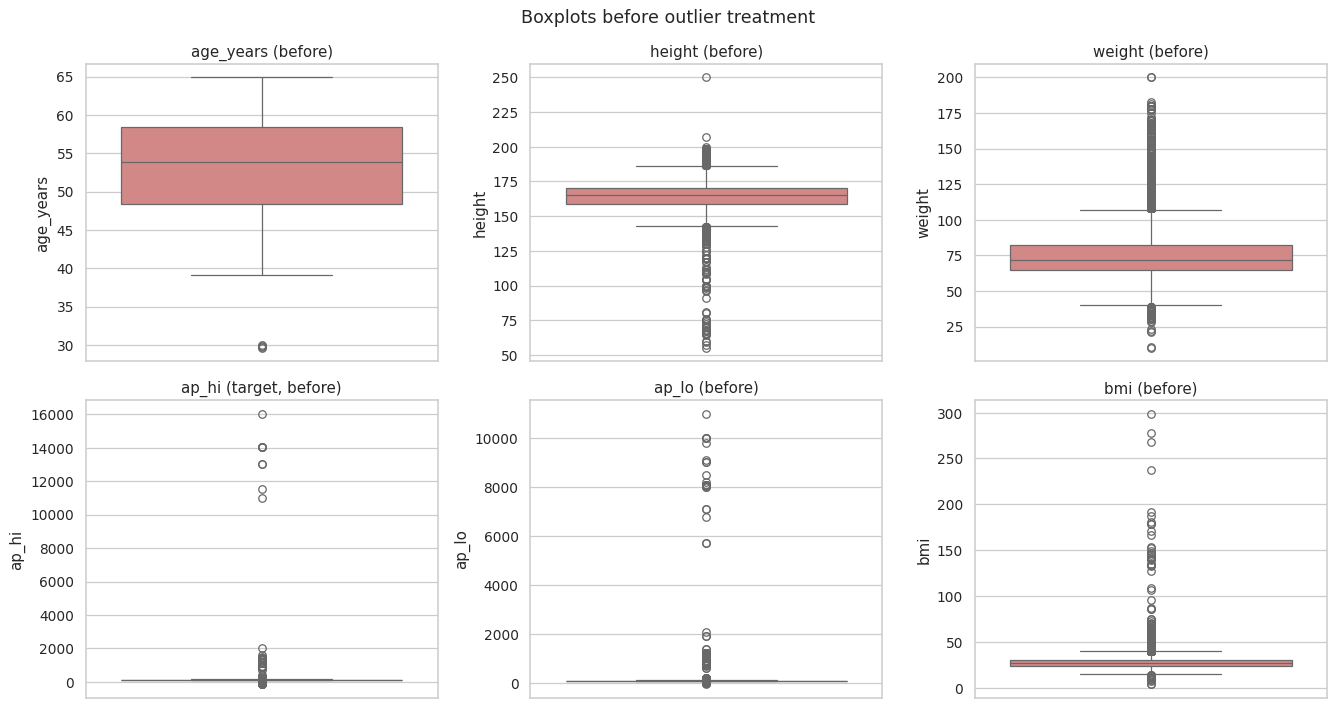

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), cont_cols):
    sns.boxplot(y=df[c], ax=ax, color="#e07b7b")
    ax.set_title(c + (" (target, before)" if c == TARGET else " (before)"))
plt.suptitle("Boxplots before outlier treatment", fontsize=14)
plt.tight_layout()
plt.show()

**Treatment:** values outside the IQR fences are **capped (winsorised)** at the fence rather than deleted. This keeps all ~70,000 observations and removes the influence of impossible values, in the predictors and in the target.

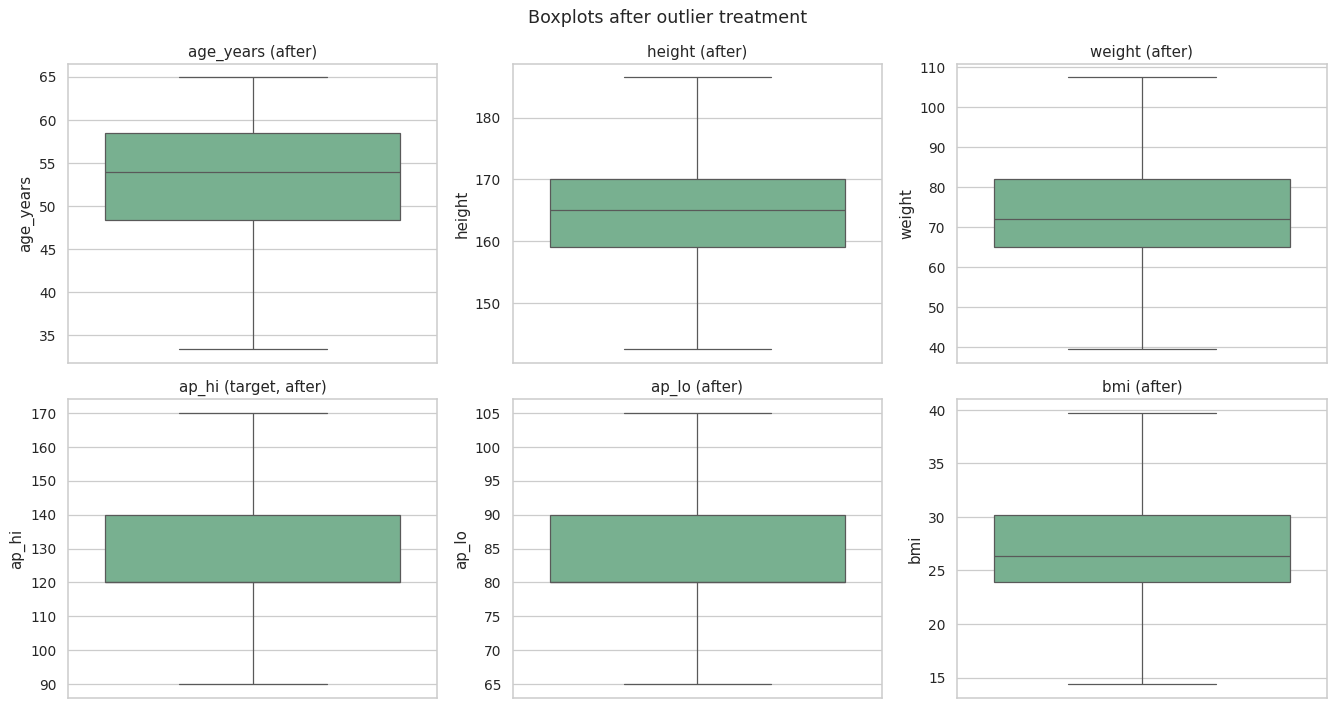

In [8]:
df_clean = df.copy()
for c in cont_cols:
    lo, hi = iqr_bounds(df[c])          # fences computed on the original data
    df_clean[c] = df_clean[c].clip(lower=lo, upper=hi)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), cont_cols):
    sns.boxplot(y=df_clean[c], ax=ax, color="#6fb98f")
    ax.set_title(c + (" (target, after)" if c == TARGET else " (after)"))
plt.suptitle("Boxplots after outlier treatment", fontsize=14)
plt.tight_layout()
plt.show()

### 3.1 Shape and `describe()` after outlier treatment

In [9]:
print("Shape after treatment:", df_clean.shape)
display(df_clean.describe().T)

Shape after treatment: (70000, 13)


,count,mean,std,min,25%,50%,75%,max
gender,70000.0,1.349571,0.476838,1.000000,1.000000,1.000000,2.000000,2.000000
height,70000.0,164.407179,7.825729,142.500000,159.000000,165.000000,170.000000,186.500000
weight,70000.0,73.925521,13.442415,39.500000,65.000000,72.000000,82.000000,107.500000
ap_hi,70000.0,126.712757,16.385671,90.000000,120.000000,120.000000,140.000000,170.000000
ap_lo,70000.0,81.779500,9.062702,65.000000,80.000000,80.000000,90.000000,105.000000
cholesterol,70000.0,1.366871,0.680250,1.000000,1.000000,1.000000,2.000000,3.000000
gluc,70000.0,1.226457,0.572270,1.000000,1.000000,1.000000,1.000000,3.000000
smoke,70000.0,0.088129,0.283484,0.000000,0.000000,0.000000,0.000000,1.000000
alco,70000.0,0.053771,0.225568,0.000000,0.000000,0.000000,0.000000,1.000000
active,70000.0,0.803729,0.397179,0.000000,1.000000,1.000000,1.000000,1.000000


## 4. Encoding, EDA, split, scaling and dimensionality reduction

In [10]:
# --- Encoding ---------------------------------------------------------------
# gender: 1/2 -> 0/1 (binary encoding)
df_clean["gender"] = df_clean["gender"].map({1: 0, 2: 1})
# cholesterol and gluc are ORDINAL (1 = normal, 2 = above normal, 3 = well above normal)
# -> the existing integer order is already the correct ordinal encoding.
# any remaining text columns (none in this dataset) would be one-hot encoded
obj_cols = df_clean.select_dtypes(include=["object", "category"]).columns.tolist()
if obj_cols:
    df_clean = pd.get_dummies(df_clean, columns=obj_cols, drop_first=True)

print("Non-numeric columns left:", df_clean.select_dtypes(exclude="number").columns.tolist())
df_clean.dtypes

Non-numeric columns left: []


gender           int64
height         float64
weight         float64
ap_hi            int64
ap_lo            int64
cholesterol      int64
gluc             int64
smoke            int64
alco             int64
active           int64
cardio           int64
age_years      float64
bmi            float64

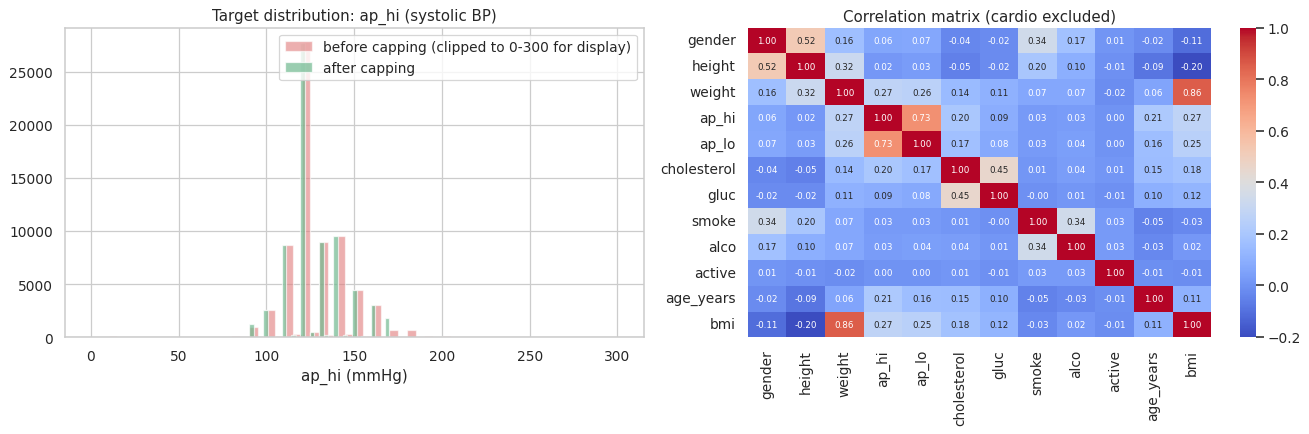

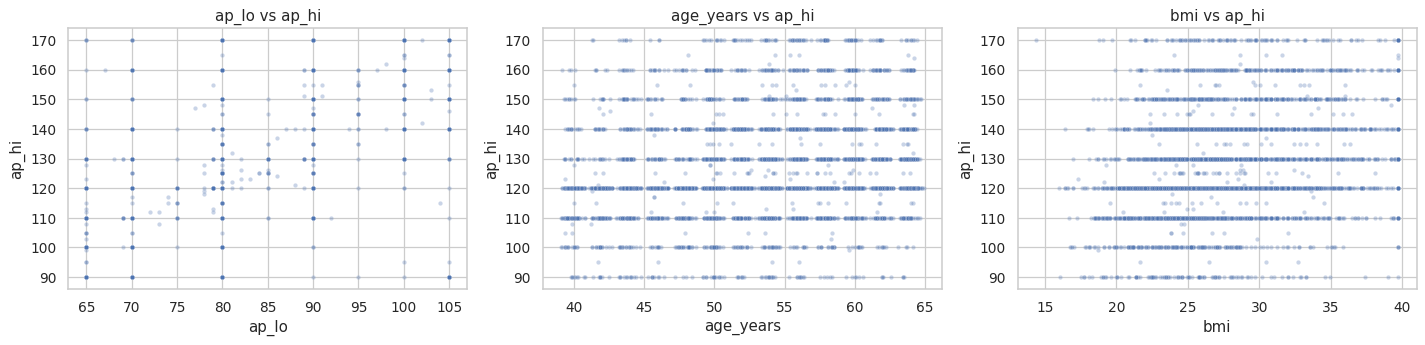

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].hist(df["ap_hi"].clip(0, 300), bins=60, alpha=0.6, label="before capping (clipped to 0-300 for display)", color="#e07b7b")
axes[0].hist(df_clean["ap_hi"], bins=30, alpha=0.7, label="after capping", color="#6fb98f")
axes[0].set_title("Target distribution: ap_hi (systolic BP)")
axes[0].set_xlabel("ap_hi (mmHg)"); axes[0].legend()
sns.heatmap(df_clean.drop(columns="cardio").corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1], annot_kws={"size": 7})
axes[1].set_title("Correlation matrix (cardio excluded)")
plt.tight_layout()
plt.show()

sample = df_clean.sample(5000, random_state=RANDOM_STATE)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, ["ap_lo", "age_years", "bmi"]):
    sns.scatterplot(x=sample[c], y=sample[TARGET], s=12, alpha=0.3, ax=ax)
    ax.set_title(f"{c} vs {TARGET}")
plt.tight_layout()
plt.show()

### 4.1 Features, target and train / test split
`cardio` is **not** used as a predictor: it is the diagnosis outcome (itself partly defined by blood pressure), so using it to predict blood pressure would be circular. `id` was already dropped.

The split is 80/20. Because `ap_hi` is continuous, temporary quantile bins are used only to **stratify** the split, so train and test have the same target distribution. The scaler and PCA are fitted on the training data only, so no information from the test set leaks into training.

In [12]:
y = df_clean[TARGET].copy()
X = df_clean.drop(columns=[TARGET, "cardio"])
print("Features:", X.columns.tolist())
print("Target leakage check:", TARGET in X.columns or "cardio" in X.columns)

stratify_bins = pd.qcut(y, q=10, labels=False, duplicates="drop")   # used only for stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=stratify_bins, random_state=RANDOM_STATE)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
pd.DataFrame({"set": ["Train", "Test"], "samples": [len(y_train), len(y_test)],
              "mean_ap_hi": [y_train.mean(), y_test.mean()],
              "std_ap_hi": [y_train.std(), y_test.std()]})

Features: ['gender', 'height', 'weight', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'age_years', 'bmi']
Target leakage check: False
X_train: (56000, 11) | X_test: (14000, 11)


,set,samples,mean_ap_hi,std_ap_hi
0,Train,56000,126.728893,16.368294
1,Test,14000,126.648214,16.455427


### 4.2 Feature scaling (StandardScaler) and dimensionality reduction (PCA)
PCA is variance based, so the features are standardised first. The number of components is chosen to retain **95 % of the variance**.

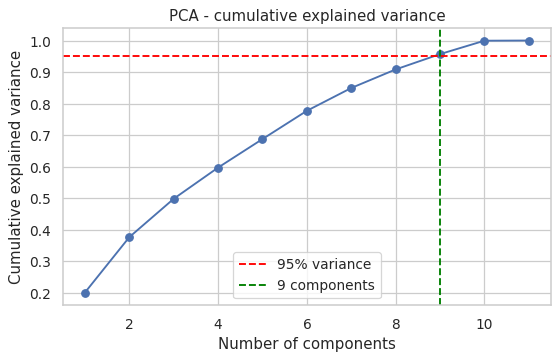

Features before PCA: 11  ->  after PCA: 9
Variance retained  : 0.957


In [13]:
scaler = StandardScaler().fit(X_train)
X_train_sc = scaler.transform(X_train)
X_test_sc = scaler.transform(X_test)

pca_full = PCA(random_state=RANDOM_STATE).fit(X_train_sc)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
n_comp = int(np.argmax(cum_var >= 0.95) + 1)

pca = PCA(n_components=n_comp, random_state=RANDOM_STATE).fit(X_train_sc)
X_train_pca = pca.transform(X_train_sc)
X_test_pca = pca.transform(X_test_sc)

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker="o")
plt.axhline(0.95, color="red", ls="--", label="95% variance")
plt.axvline(n_comp, color="green", ls="--", label=f"{n_comp} components")
plt.xlabel("Number of components"); plt.ylabel("Cumulative explained variance")
plt.title("PCA - cumulative explained variance"); plt.legend()
plt.show()

print(f"Features before PCA: {X_train_sc.shape[1]}  ->  after PCA: {X_train_pca.shape[1]}")
print(f"Variance retained  : {pca.explained_variance_ratio_.sum():.3f}")

## 5. Model training with hyper-parameter tuning (all 10 models)
Every model - from both notebooks - is trained on the **same PCA-transformed training data** and evaluated on the same test set.

Each model is tuned with `GridSearchCV` (3-fold, scored on R2) on a random 15,000-row sample of the training set to keep run-time reasonable, and the best parameters are then used to **refit the model on the full training set**. The test set is only used for the final evaluation.
**Exception - SVR:** as in the second original notebook, kernel SVR is too expensive for the full training set, so it is tuned **and trained** on a fixed 5,000-row sample, and then evaluated on the full test set like every other model.

In [14]:
results = {}

def tune_and_fit(name, estimator, param_grid, group, search_size=15000, refit_on_sample=False):
    t0 = time.time()
    X_sub, _, y_sub, _ = train_test_split(X_train_pca, y_train, train_size=search_size,
                                          random_state=RANDOM_STATE)
    gs = GridSearchCV(estimator, param_grid, cv=3, scoring="r2", n_jobs=-1)
    gs.fit(X_sub, y_sub)

    best = clone(estimator).set_params(**gs.best_params_)
    fit_X, fit_y = (X_sub, y_sub) if refit_on_sample else (X_train_pca, y_train)
    best.fit(fit_X, fit_y)

    results[name] = {
        "group": group,
        "model": best,
        "best_params": gs.best_params_,
        "cv_r2": gs.best_score_,
        "y_pred": best.predict(X_test_pca),
        "train_r2": r2_score(fit_y, best.predict(fit_X)),
        "fit_rows": len(fit_y),
        "time_s": time.time() - t0,
    }
    print(f"{name:<24} best params: {gs.best_params_}")
    print(f"{'':<24} CV R2 = {gs.best_score_:.4f} | trained on {len(fit_y):,} rows | total time = {time.time() - t0:.0f}s")

# PART A - Algorithms from the first regression notebook

### 5.1 Linear Regression
**Purpose:** baseline model. It has no real hyper-parameters (only `fit_intercept` is checked). Coefficients are interpreted in section 6.4.

In [15]:
tune_and_fit("Linear Regression", LinearRegression(),
             {"fit_intercept": [True, False]}, group="A")

Linear Regression        best params: {'fit_intercept': True}
                         CV R2 = 0.5490 | trained on 56,000 rows | total time = 0s


### 5.2 Ridge Regression (L2 regularisation, tuned: `alpha`)

In [16]:
tune_and_fit("Ridge", Ridge(random_state=RANDOM_STATE),
             {"alpha": [0.01, 0.1, 1.0, 10.0, 100.0]}, group="A")

Ridge                    best params: {'alpha': 1.0}
                         CV R2 = 0.5490 | trained on 56,000 rows | total time = 0s


### 5.3 Lasso Regression (L1 regularisation, tuned: `alpha`)

In [17]:
tune_and_fit("Lasso", Lasso(max_iter=20000, random_state=RANDOM_STATE),
             {"alpha": [0.001, 0.01, 0.1, 1.0, 10.0]}, group="A")

Lasso                    best params: {'alpha': 0.001}
                         CV R2 = 0.5490 | trained on 56,000 rows | total time = 0s


### 5.4 ElasticNet Regression (L1 + L2, tuned: `alpha`, `l1_ratio`)

In [18]:
tune_and_fit("ElasticNet", ElasticNet(max_iter=20000, random_state=RANDOM_STATE),
             {"alpha": [0.001, 0.01, 0.1, 1.0], "l1_ratio": [0.2, 0.5, 0.8]}, group="A")

ElasticNet               best params: {'alpha': 0.001, 'l1_ratio': 0.5}
                         CV R2 = 0.5490 | trained on 56,000 rows | total time = 0s


### 5.5 Polynomial Regression
Predictors are expanded into polynomial terms, standardised and fed to a Linear Regression. The **polynomial degree (1, 2 or 3)** is tuned.

In [19]:
tune_and_fit(
    "Polynomial Regression",
    Pipeline([("poly", PolynomialFeatures(include_bias=False)),
              ("scale_poly", StandardScaler()),
              ("regressor", LinearRegression())]),
    {"poly__degree": [1, 2, 3]}, group="A")

Polynomial Regression    best params: {'poly__degree': 2}
                         CV R2 = 0.5507 | trained on 56,000 rows | total time = 2s


# PART B - Algorithms from the second regression notebook

### 5.6 Decision Tree Regressor (tuned: `max_depth`, `min_samples_split`)

In [20]:
tune_and_fit("Decision Tree", DecisionTreeRegressor(random_state=RANDOM_STATE),
             {"max_depth": [3, 5, 8, 10, 15, 20, None], "min_samples_split": [2, 5, 10]}, group="B")

Decision Tree            best params: {'max_depth': 8, 'min_samples_split': 10}
                         CV R2 = 0.4608 | trained on 56,000 rows | total time = 7s


### 5.7 Random Forest Regressor (tuned: `n_estimators`, `max_depth`, `min_samples_split`)

In [21]:
tune_and_fit("Random Forest", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
             {"n_estimators": [100, 200], "max_depth": [10, 20], "min_samples_split": [2, 5]}, group="B")

Random Forest            best params: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 200}
                         CV R2 = 0.5428 | trained on 56,000 rows | total time = 367s


### 5.8 Gradient Boosting Regressor (tuned: `learning_rate`, `n_estimators`, `max_depth`)

In [22]:
tune_and_fit("Gradient Boosting", GradientBoostingRegressor(random_state=RANDOM_STATE),
             {"learning_rate": [0.03, 0.05, 0.10], "n_estimators": [100, 200], "max_depth": [2, 3]}, group="B")

Gradient Boosting        best params: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200}
                         CV R2 = 0.5491 | trained on 56,000 rows | total time = 233s


### 5.9 Support Vector Regressor (SVR)
Tuned: `C`, `epsilon` and `kernel` (RBF / linear). As explained above, SVR is tuned and trained on a fixed 5,000-row sample and evaluated on the full test set.

In [23]:
tune_and_fit("SVR", SVR(cache_size=1000),
             {"C": [1, 10, 50], "epsilon": [0.05, 0.1, 0.2], "kernel": ["rbf", "linear"]},
             group="B", search_size=5000, refit_on_sample=True)

SVR                      best params: {'C': 1, 'epsilon': 0.2, 'kernel': 'linear'}
                         CV R2 = 0.5298 | trained on 5,000 rows | total time = 79s


### 5.10 K-Nearest Neighbors Regressor (tuned: `k`, weighting)

In [24]:
tune_and_fit("KNN", KNeighborsRegressor(),
             {"n_neighbors": [3, 5, 10, 15, 20, 30, 50], "weights": ["uniform", "distance"]}, group="B")

KNN                      best params: {'n_neighbors': 20, 'weights': 'uniform'}
                         CV R2 = 0.5188 | trained on 56,000 rows | total time = 15s


## 6. Results - all 10 models

### 6.1 Evaluation metrics table (test set)

In [25]:
rows = []
for name, r in results.items():
    rows.append({
        "Model": name,
        "Part": r["group"],
        "R2": r2_score(y_test, r["y_pred"]),
        "RMSE": np.sqrt(mean_squared_error(y_test, r["y_pred"])),
        "MAE": mean_absolute_error(y_test, r["y_pred"]),
        "Train R2": r["train_r2"],
        "CV R2": r["cv_r2"],
        "Time (s)": r["time_s"],
    })
results_df = pd.DataFrame(rows).set_index("Model").sort_values("R2", ascending=False)
results_df["Overfit gap (Train R2 - Test R2)"] = results_df["Train R2"] - results_df["R2"]
results_df.round(4)

,Part,R2,RMSE,MAE,Train R2,CV R2,Time (s),Overfit gap (Train R2 - Test R2)
Model,,,,,,,,
Random Forest,B,0.5326,11.2492,7.6263,0.6355,0.5428,367.4273,0.1029
Gradient Boosting,B,0.5315,11.2628,7.7183,0.5715,0.5491,233.0192,0.0400
Polynomial Regression,A,0.5307,11.2730,7.8344,0.5568,0.5507,1.8713,0.0261
ElasticNet,A,0.5286,11.2971,7.9422,0.5525,0.5490,0.2199,0.0238
Lasso,A,0.5286,11.2973,7.9418,0.5525,0.5490,0.1257,0.0238
Ridge,A,0.5286,11.2974,7.9416,0.5525,0.5490,0.1686,0.0238
Linear Regression,A,0.5286,11.2974,7.9416,0.5525,0.5490,0.1460,0.0238
KNN,B,0.5143,11.4681,7.8848,0.5832,0.5188,14.5355,0.0690
SVR,B,0.5039,11.5902,7.6176,0.5293,0.5298,79.2500,0.0254


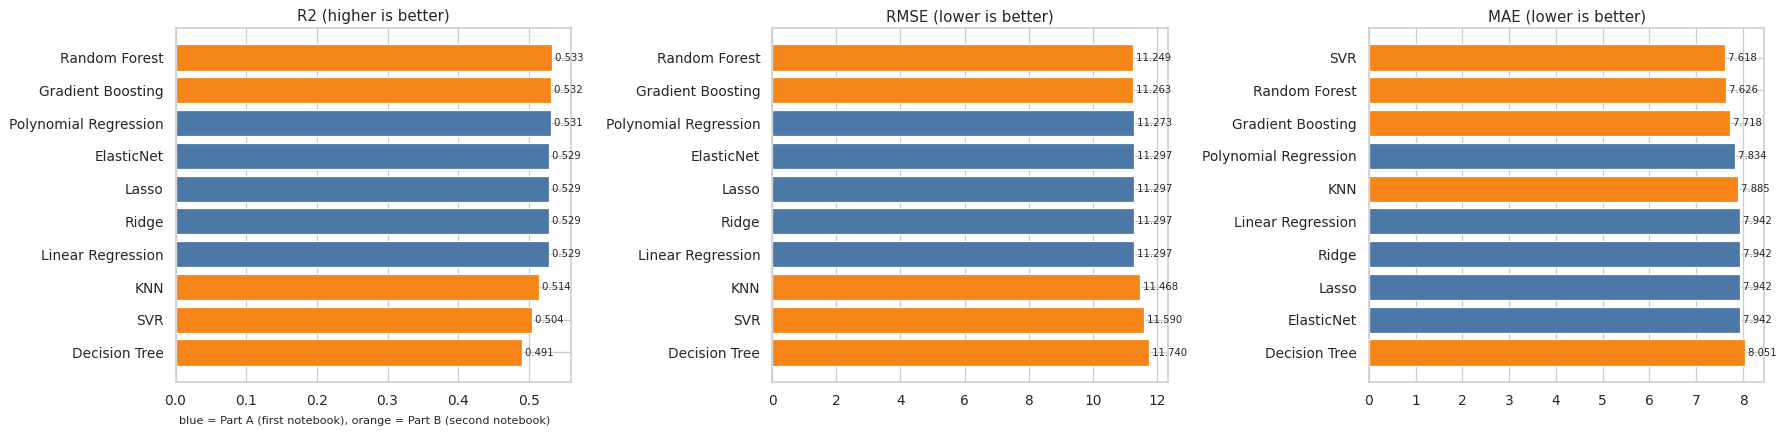

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, (metric, better) in zip(axes, [("R2", "higher is better"), ("RMSE", "lower is better"), ("MAE", "lower is better")]):
    vals = results_df[metric].sort_values(ascending=(metric == "R2"))
    colors = ["#4c78a8" if results_df.loc[m, "Part"] == "A" else "#f58518" for m in vals.index]
    ax.barh(vals.index, vals.values, color=colors)
    ax.set_title(f"{metric} ({better})")
    for i, v in enumerate(vals.values):
        ax.text(v, i, f" {v:.3f}", va="center", fontsize=8)
axes[0].text(0.01, -0.12, "blue = Part A (first notebook), orange = Part B (second notebook)",
             transform=axes[0].transAxes, fontsize=9)
plt.tight_layout()
plt.show()

### 6.2 Predicted vs actual (all 10 models)

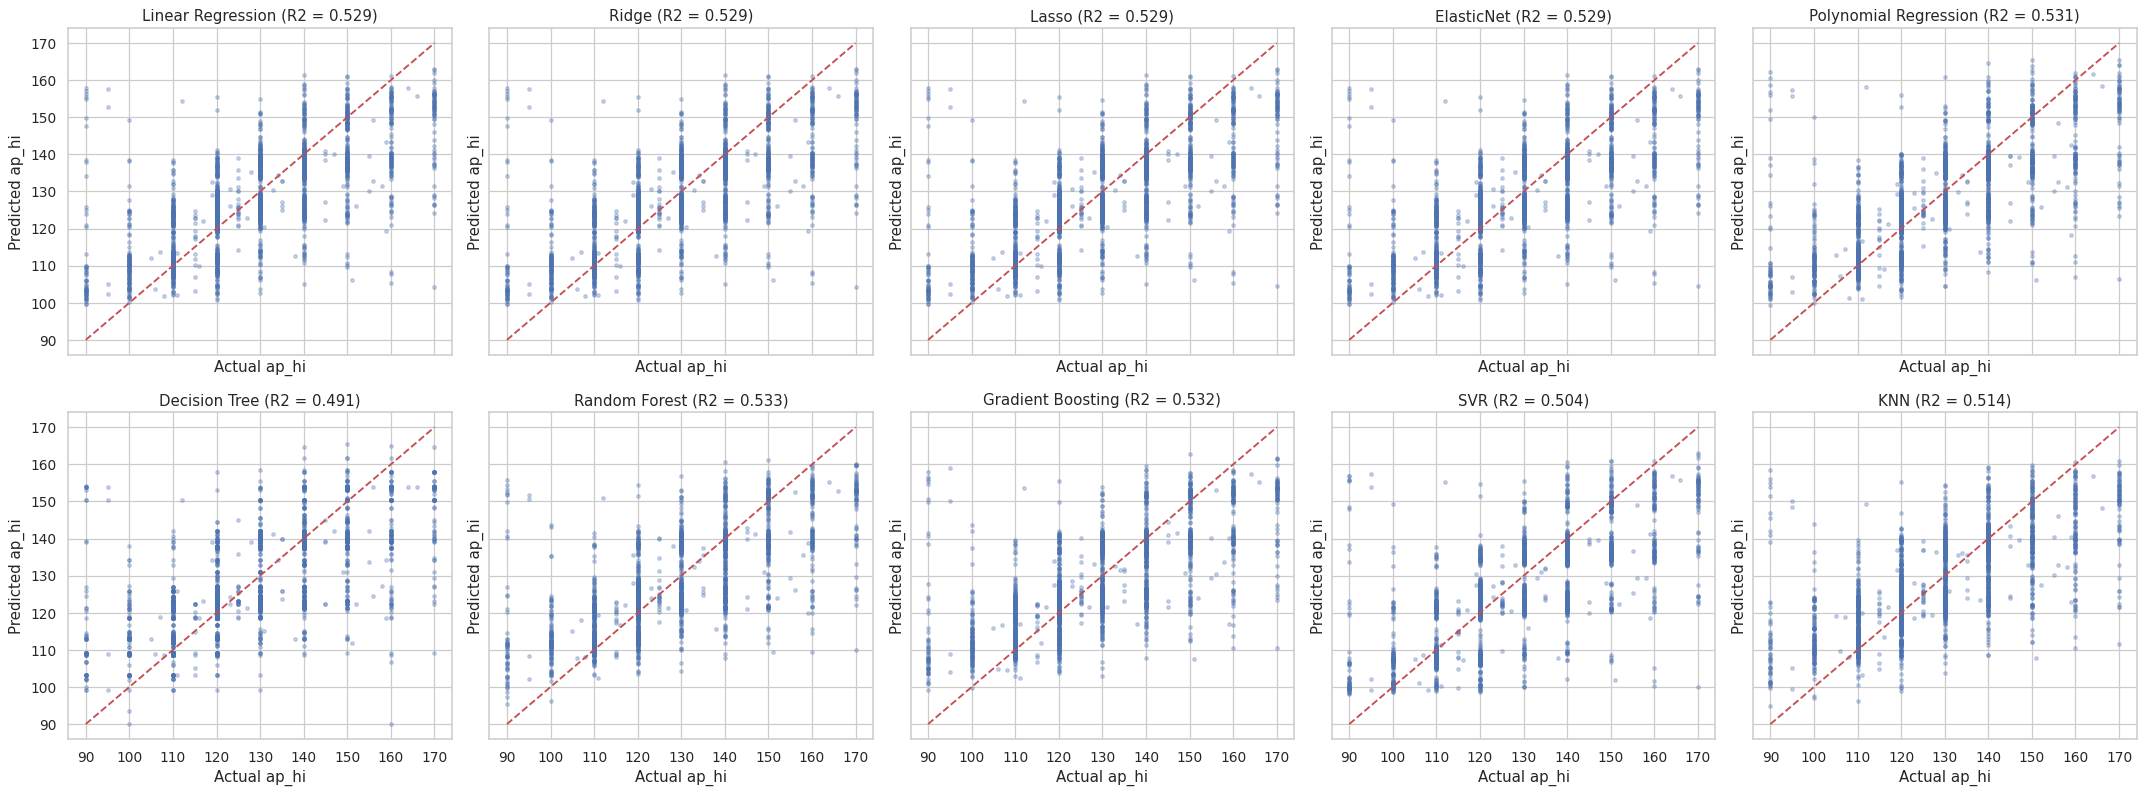

In [27]:
fig, axes = plt.subplots(2, 5, figsize=(24, 9), sharex=True, sharey=True)
lo, hi = float(y_test.min()), float(y_test.max())
rng = np.random.RandomState(RANDOM_STATE)
idx = rng.choice(len(y_test), 3000, replace=False)
for ax, (name, r) in zip(axes.ravel(), results.items()):
    ax.scatter(y_test.values[idx], r["y_pred"][idx], s=8, alpha=0.3)
    ax.plot([lo, hi], [lo, hi], "r--")
    ax.set_title(f"{name} (R2 = {r2_score(y_test, r['y_pred']):.3f})")
    ax.set_xlabel("Actual ap_hi"); ax.set_ylabel("Predicted ap_hi")
plt.tight_layout()
plt.show()

### 6.3 Best model - residual analysis

Best model by test R2: Random Forest
Mean residual: -0.0348 | Residual std: 11.2491


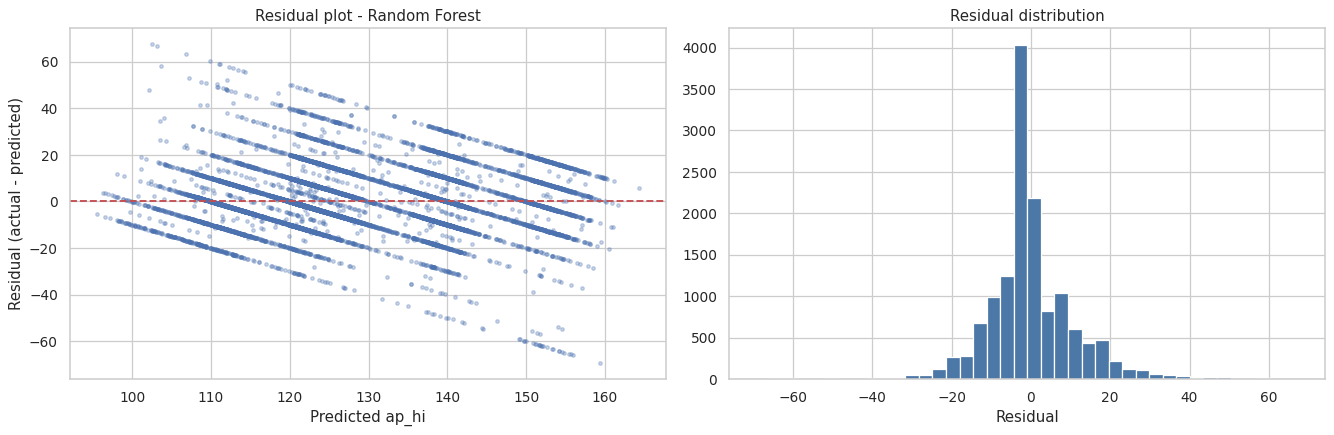

In [28]:
best_name = results_df.index[0]
best_pred = results[best_name]["y_pred"]
residuals = y_test.values - best_pred
print("Best model by test R2:", best_name)
print(f"Mean residual: {residuals.mean():.4f} | Residual std: {residuals.std():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].scatter(best_pred, residuals, s=8, alpha=0.3)
axes[0].axhline(0, color="r", ls="--")
axes[0].set_xlabel("Predicted ap_hi"); axes[0].set_ylabel("Residual (actual - predicted)")
axes[0].set_title(f"Residual plot - {best_name}")
axes[1].hist(residuals, bins=40, color="#4c78a8")
axes[1].set_title("Residual distribution"); axes[1].set_xlabel("Residual")
plt.tight_layout()
plt.show()

### 6.4 5-fold cross-validation for the two best models

In [29]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
top_two = results_df.index[:2].tolist()
print("Two best models by test R2:", top_two)

# SVR was trained on its own 5,000-row sample, so it is cross-validated on that sample as well
X_svr_fit, _, y_svr_fit, _ = train_test_split(X_train_pca, y_train, train_size=5000, random_state=RANDOM_STATE)

cv_rows = []
for name in top_two:
    cv_X, cv_y = (X_svr_fit, y_svr_fit) if name == "SVR" else (X_train_pca, y_train)
    scores = cross_val_score(clone(results[name]["model"]), cv_X, cv_y, cv=cv, scoring="r2", n_jobs=-1)
    row = {"Model": name}
    row.update({f"Fold {i+1} R2": s for i, s in enumerate(scores)})
    row.update({"Mean CV R2": scores.mean(), "Std CV R2": scores.std()})
    cv_rows.append(row)
pd.DataFrame(cv_rows).round(4)

Two best models by test R2: ['Random Forest', 'Gradient Boosting']


,Model,Fold 1 R2,Fold 2 R2,Fold 3 R2,Fold 4 R2,Fold 5 R2,Mean CV R2,Std CV R2
0,Random Forest,0.5618,0.5587,0.5578,0.5531,0.5530,0.5569,0.0034
1,Gradient Boosting,0.5622,0.5570,0.5553,0.5528,0.5556,0.5566,0.0031


### 6.5 Interpretation: coefficients, tree and feature importance
The models above were trained on PCA components (PC1, PC2, ...), which are hard to read medically. For interpretation, this section uses the **original scaled features**:
Linear Regression coefficients, a depth-3 regression tree (visual) and Random Forest feature importances (using the tuned Random Forest parameters).

In [30]:
feature_names = list(X.columns)

lin = LinearRegression().fit(X_train_sc, y_train)
coef = pd.DataFrame({"Feature": feature_names, "Coefficient (mmHg per 1 std)": lin.coef_})
coef = coef.reindex(coef.iloc[:, 1].abs().sort_values(ascending=False).index).reset_index(drop=True)
print(f"Intercept: {lin.intercept_:.3f} | Test R2 on original scaled features: {lin.score(X_test_sc, y_test):.4f}")
coef.round(4)

Intercept: 126.729 | Test R2 on original scaled features: 0.5288


,Feature,Coefficient (mmHg per 1 std)
0,ap_lo,11.1630
1,age_years,1.4215
2,bmi,1.3057
3,cholesterol,0.9595
4,gender,0.3516
5,weight,0.1652
6,smoke,0.1233
7,gluc,-0.0960
8,alco,-0.0913
9,height,0.0892


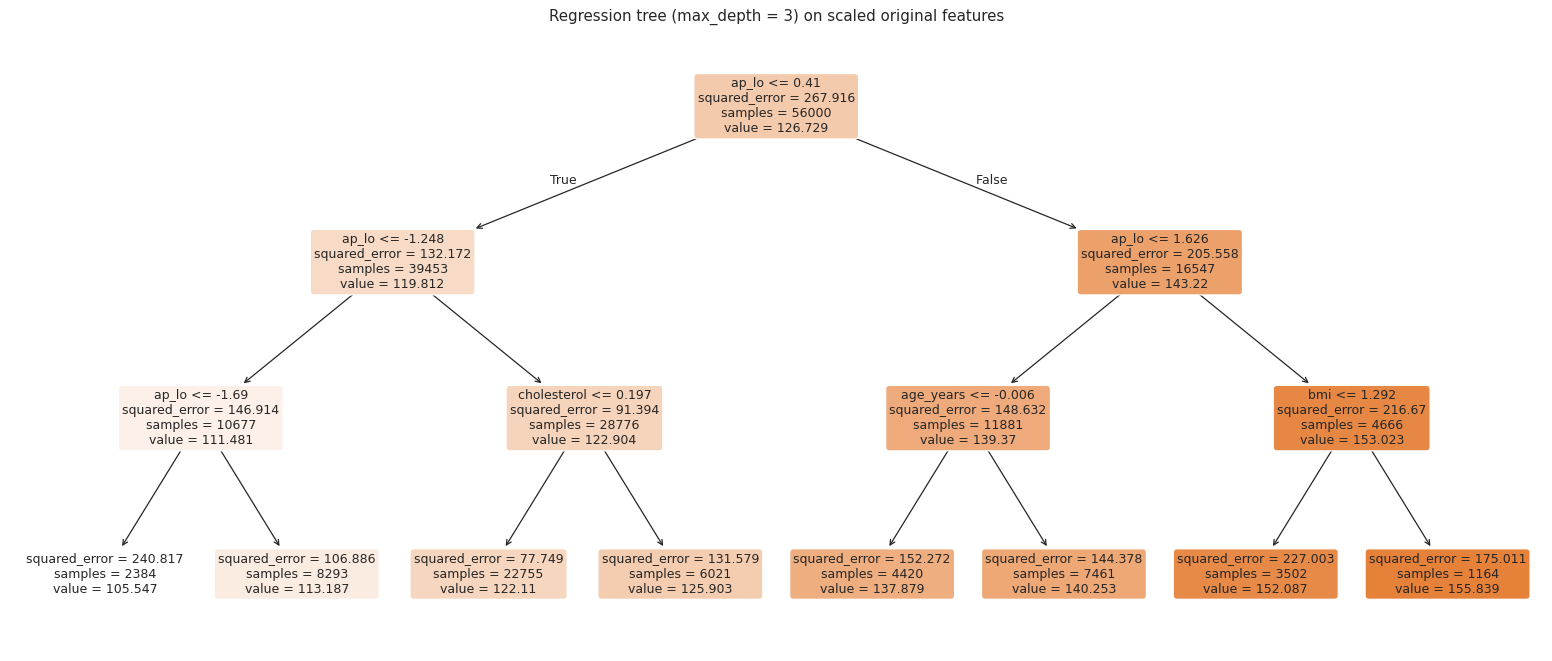

Depth-3 tree test R2: 0.5184


In [31]:
dt = DecisionTreeRegressor(max_depth=3, random_state=RANDOM_STATE).fit(X_train_sc, y_train)
plt.figure(figsize=(22, 9))
plot_tree(dt, feature_names=feature_names, filled=True, rounded=True, fontsize=10)
plt.title("Regression tree (max_depth = 3) on scaled original features")
plt.show()
print(f"Depth-3 tree test R2: {dt.score(X_test_sc, y_test):.4f}")

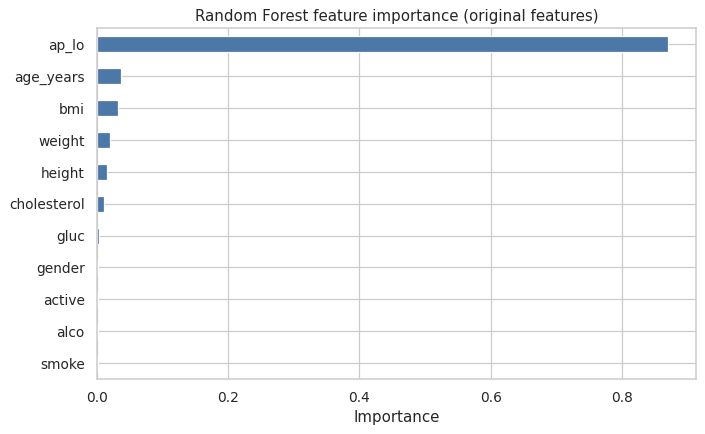

Random Forest on original scaled features - test R2: 0.5366


ap_lo          0.8694
age_years      0.0376
bmi            0.0326
weight         0.0201
height         0.0165
cholesterol    0.0119
gluc           0.0040
gender         0.0024
active         0.0021
alco           0.0019
smoke          0.0014

In [32]:
rf_interp = RandomForestRegressor(**results["Random Forest"]["best_params"],
                                  random_state=RANDOM_STATE, n_jobs=-1).fit(X_train_sc, y_train)
imp = pd.Series(rf_interp.feature_importances_, index=feature_names).sort_values()

plt.figure(figsize=(8, 5))
imp.plot(kind="barh", color="#4c78a8")
plt.title("Random Forest feature importance (original features)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()
print(f"Random Forest on original scaled features - test R2: {rf_interp.score(X_test_sc, y_test):.4f}")
imp.sort_values(ascending=False).round(4)

## 7. Final validation checks

In [33]:
print("- Missing values after cleaning :", int(df_clean.isnull().sum().sum()))
print("- Target in feature matrix      :", TARGET in X.columns)
print("- cardio in feature matrix      :", "cardio" in X.columns)
print("- Train / test split            :", f"{len(X_train):,} / {len(X_test):,}")
print("- Features before / after PCA   :", f"{X_train_sc.shape[1]} / {X_train_pca.shape[1]}")
print("- Models trained                :", len(results))

assert df_clean.isnull().sum().sum() == 0
assert TARGET not in X.columns and "cardio" not in X.columns
assert len(results) == 10
print("\nAll validation checks passed.")

- Missing values after cleaning : 0
- Target in feature matrix      : False
- cardio in feature matrix      : False
- Train / test split            : 56,000 / 14,000
- Features before / after PCA   : 11 / 9
- Models trained                : 10

All validation checks passed.


## 8. Inference and conclusion

### 8.1 What the data showed
- **Data quality:** no missing values and no duplicates, but the blood-pressure columns contained clearly invalid readings (negative values, `ap_hi` up to 16,020, 1,236 rows where diastolic >= systolic). Because `ap_hi` is also the **target**, these errors would badly distort training and evaluation. IQR capping (target fences 90-170 mmHg) fixed them without losing any of the 70,000 rows. Note that all R2, RMSE and MAE values below are measured against this capped target.
- **Target:** after capping, `ap_hi` has a mean of about 127 mmHg and a standard deviation of about 16 mmHg. A model that always predicts the mean would have R2 = 0, so this is the baseline to beat.
- **Dimensionality reduction:** PCA reduced 11 features to 9 components while keeping about 95.7 % of the variance. All 10 models were trained on exactly the same transformed data, so the comparison is like-for-like.
- **Main drivers of systolic pressure** (Random Forest importance and Linear Regression coefficients on the original features agree): diastolic pressure `ap_lo` dominates (about 87 % of the importance; about +11 mmHg of `ap_hi` per one standard deviation of `ap_lo`). The remaining features add little: `age_years` (+1.4 mmHg per std), `bmi` (+1.3), `cholesterol` (+1.0) and `gender` (+0.4). Smoking, alcohol, glucose, activity, height and weight are close to zero.

### 8.2 Model ranking (test set, 14,000 patients, sorted by R2)

| Rank | Model | Part | R2 | RMSE (mmHg) | MAE (mmHg) |
|---|---|---|---|---|---|
| 1 | **Random Forest** | B | **0.5326** | **11.25** | 7.63 |
| 2 | Gradient Boosting | B | 0.5315 | 11.26 | 7.72 |
| 3 | Polynomial Regression (degree 2) | A | 0.5307 | 11.27 | 7.83 |
| 4 | ElasticNet | A | 0.5286 | 11.30 | 7.94 |
| 4 | Lasso | A | 0.5286 | 11.30 | 7.94 |
| 4 | Ridge | A | 0.5286 | 11.30 | 7.94 |
| 4 | Linear Regression | A | 0.5286 | 11.30 | 7.94 |
| 8 | KNN | B | 0.5143 | 11.47 | 7.88 |
| 9 | SVR | B | 0.5039 | 11.59 | **7.62** |
| 10 | Decision Tree | B | 0.4909 | 11.74 | 8.05 |

5-fold cross-validated R2 on the training set for the two best models: Random Forest 0.557 (std 0.003) and Gradient Boosting 0.557 (std 0.003), so their results are stable and essentially identical.

### 8.3 Which model is better?
- **Best by test R2 and RMSE: Random Forest** (R2 0.533, RMSE 11.25 mmHg), with **Gradient Boosting** a hair behind (0.532). The gap between them is 0.001 R2 and both have the same cross-validated R2, so they should be treated as tied.
- **The regularised linear models add nothing here.** Linear, Ridge, Lasso and ElasticNet give identical results (R2 0.5286). With only 9 PCA components and 56,000 training rows there is nothing to regularise, and the tuned `alpha` values end up tiny. Their value in this project is as a baseline.
- **Polynomial Regression (degree 2) is the best Part A model** (R2 0.531) and is within 0.002 of the best model overall, while training in about 2 seconds versus about 6 minutes for Random Forest on the machine used. Allowing curved relationships helps slightly; degree 3 did not improve the cross-validated score.
- **SVR has the lowest MAE** (7.62 mmHg) although its R2 is lower (0.504). It is trained on only 5,000 rows, so it is the least data-hungry model; the lower R2 means it makes some larger errors than the forests.
- **Weakest: Decision Tree** (R2 0.491, RMSE 11.74): a single tree is clearly worse than the ensembles built from many trees, which shows the benefit of averaging (Random Forest) and boosting.
- **Overfitting:** Random Forest has the largest train/test gap (about 10 points of R2), followed by KNN (7) and the Decision Tree (7); the linear models, Polynomial Regression, SVR and Gradient Boosting stay within 2-4 points.
- **The differences are small.** The top seven models are within about 0.5 R2 points of each other (0.529-0.533), so the ranking among them is not decisive.

### 8.4 Observations and caveats
- The best models only reach **R2 of about 0.53** (typical error about 11 mmHg). Almost all of the explainable variance comes from one variable, `ap_lo`: systolic and diastolic pressure are strongly related by physiology, and the other features (age, BMI, cholesterol, lifestyle) explain very little extra. Since all 10 algorithms plateau at nearly the same score, the limit comes from the information in the data, not from the choice of algorithm. Better predictors (for example heart rate, medication, or repeated measurements) would help more than further tuning.
- Using `ap_lo` as a predictor makes the task easier but less clinically meaningful: predicting one blood-pressure reading from the other mostly confirms that they move together.
- `cardio` was deliberately excluded from the predictors: it is a diagnosis that is partly defined by blood pressure, so including it would be circular.
- Models were trained on PCA components, which keeps the comparison fair but makes them harder to read, which is why the coefficients, tree and importances use the original features. Tree-based models do not need PCA.
- Hyper-parameters were tuned on a 15,000-row sample (5,000 rows for SVR, which is also trained on that sample) for speed, so full-data tuning could shift the ranking slightly.

**Conclusion:** **Random Forest** (tied with **Gradient Boosting**) is the best regressor for systolic blood pressure on this dataset, but the simple **Polynomial Regression** is almost as accurate and far faster and simpler, so it is the practical choice. Diastolic pressure is by far the strongest predictor of systolic pressure, followed (weakly) by age, BMI and cholesterol.